In [4]:
import os
import numpy as np
import pandas as pd
import scanpy as sc
from scipy.io import mmread
import anndata

In [5]:
sc.__version__

'1.9.3'

In [6]:
adata = sc.read_mtx('/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/raw_datasets/treutlein/treutlein.mtx').T

In [7]:
adata.X.max()

4835.0

In [8]:
cellnames = pd.read_csv("/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/raw_datasets/treutlein/treutlein_cellnames.csv")["x"]

In [9]:
genenames =  pd.read_csv("/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/raw_datasets/treutlein/treutlein_genenames.csv")["x"]


In [13]:
celltypes = pd.read_csv("/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/raw_datasets/treutlein/treutlein_celltype.csv")["annot_ct"]


In [14]:
celltypes

0        choroid_plexus
1        choroid_plexus
2        choroid_plexus
3        choroid_plexus
4        choroid_plexus
              ...      
44270               epi
44271               epi
44272               epi
44273               epi
44274               epi
Name: annot_ct, Length: 44275, dtype: object

In [15]:
adata.obs_names = cellnames
adata.var_names = genenames

In [16]:
barcodes = pd.read_csv("/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/raw_datasets/treutlein/treutlein_GeneBarcodeMerge.csv")

In [17]:
barcodes = barcodes.set_index("Unnamed: 0")
barcodes

,GeneBarcodeMerge
Unnamed: 0,
d15_1_iDOXd15.1_AAACCCAAGCTTAGTC,iDOXd15.1_AAGGAACGCCA_ACGGTGCACGT
d15_1_iDOXd15.1_AAAGGATCAGCTGTAT,iDOXd15.1_ACAAACGACCA_AGAAGGAGATA_AGCATGAGGCA
d15_1_iDOXd15.1_AAAGGATCATCACGGC,iDOXd15.1_AAGGAACGCTT_TCTGGGAGGCA
d15_1_iDOXd15.1_AAAGGATTCAAGTCGT,NaN
d15_1_iDOXd15.1_AAAGGGCTCCCTCATG,NaN
...,...
LTv2_NEd32_iNE32_TTCGGTCCACTGCCAG,iNE32_AAAACAGTAGA_AGGGAAAGCGA
LTv2_NEd32_iNE32_TTCTTAGAGGAACTGC,iNE32_AAAACAGTAGA_AGGGAAAGCGA
LTv2_NEd32_iNE32_TTGGAACGTAAAGGAG,iNE32_AAAACAGTAGA_AGGGAAAGCGA


In [18]:
adata.obs["barcode"] = adata.obs_names.map(barcodes["GeneBarcodeMerge"])

In [19]:
adata.obs["barcode"]

x
d15_1_iDOXd15.1_AAACCCAAGCTTAGTC                 iDOXd15.1_AAGGAACGCCA_ACGGTGCACGT
d15_1_iDOXd15.1_AAAGGATCAGCTGTAT     iDOXd15.1_ACAAACGACCA_AGAAGGAGATA_AGCATGAGGCA
d15_1_iDOXd15.1_AAAGGATCATCACGGC                 iDOXd15.1_AAGGAACGCTT_TCTGGGAGGCA
d15_1_iDOXd15.1_AAAGGATTCAAGTCGT                                               NaN
d15_1_iDOXd15.1_AAAGGGCTCCCTCATG                                               NaN
                                                         ...                      
LTv2_NEd32_iNE32_TTCGGTCCACTGCCAG                    iNE32_AAAACAGTAGA_AGGGAAAGCGA
LTv2_NEd32_iNE32_TTCTTAGAGGAACTGC                    iNE32_AAAACAGTAGA_AGGGAAAGCGA
LTv2_NEd32_iNE32_TTGGAACGTAAAGGAG                    iNE32_AAAACAGTAGA_AGGGAAAGCGA
LTv2_NEd32_iNE32_TTGTAGGCAAACGTGG                    iNE32_AAAACAGTAGA_AGGGAAAGCGA
LTv2_NEd32_iNE32_TTTGCGCAGTGCGTGA                    iNE32_AAAACAGTAGA_AGGGAAAGCGA
Name: barcode, Length: 44275, dtype: object

In [28]:
adata.obs["cell_type"] = celltypes.to_numpy()

In [29]:
adata_no_nan = adata[~adata.obs["barcode"].isna()]

In [32]:
adata_no_nan.obs["cell_type"].unique()

array(['choroid_plexus', 'dien_neuron', 'dien_NPC', 'tel_NPC', 'retina',
       'tel_neuron', 'hind_NPC', 'hind_neuron', 'pns', 'mesen', 'nc',
       'epi', 'mg'], dtype=object)

In [33]:
# check MT percentage 

# Mark MT genes
adata_no_nan.var["mt"] = adata_no_nan.var_names.str.upper().str.startswith("MT-")

# Compute MT % per cell
sc.pp.calculate_qc_metrics(adata_no_nan, qc_vars=["mt"], inplace=True)


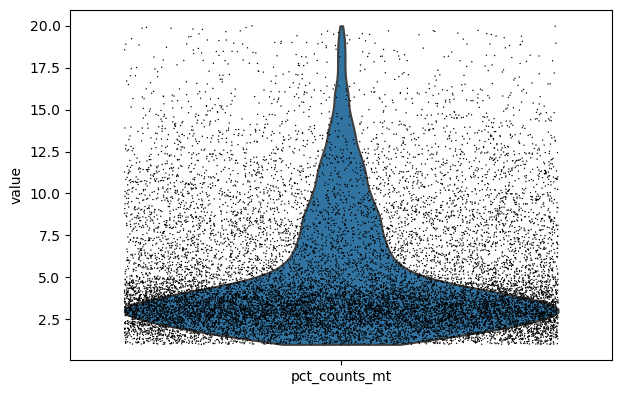

In [34]:
#adata_no_nan.var_names_make_unique()
sc.pl.violin(adata_no_nan, 'pct_counts_mt', jitter=0.4)

In [35]:
# not filtering more since authors already applied filtering at 20%


In [36]:
sc.pp.filter_cells(adata_no_nan, min_genes=100)
sc.pp.filter_genes(adata_no_nan, min_cells=2)

In [37]:
sc.pp.normalize_total(adata_no_nan , target_sum=1e4)
sc.pp.log1p(adata_no_nan)

adata_filtered = adata_no_nan

In [46]:
df = pd.DataFrame(adata_filtered.X.todense(), columns = adata_filtered.var_names)

In [47]:
df["cell_type"] = adata_filtered.obs["cell_type"].to_numpy()

In [48]:
df["barcode"] = adata_filtered.obs["barcode"].values

In [49]:
barcode_df = {}
k = 0
for i in df["barcode"].unique():
    barcode_df[i] = k
    k +=1

In [50]:
df["barcode_cont"] = df["barcode"].map(barcode_df)

In [51]:
df

x,FO538757.2,AP006222.2,LINC00115,FAM41C,SAMD11,NOC2L,KLHL17,PLEKHN1,HES4,ISG15,...,AC136352.5,AC145212.4,AC145212.2,AC007325.2,AL354822.1,eGFP,Tomato,cell_type,barcode,barcode_cont
0,0.000000,1.262945,0.000000,0.000000,0.000000,0.0,0.000000,0.0,1.262945,0.000000,...,0.0,0.0,0.0,0.0,0.000000,0.000000,3.271779,choroid_plexus,iDOXd15.1_AAGGAACGCCA_ACGGTGCACGT,0
1,0.000000,1.314547,0.000000,0.000000,0.000000,0.0,0.000000,0.0,2.215849,0.000000,...,0.0,0.0,0.0,0.0,0.000000,0.000000,2.998800,choroid_plexus,iDOXd15.1_ACAAACGACCA_AGAAGGAGATA_AGCATGAGGCA,1
2,0.000000,0.000000,0.790053,0.000000,1.225840,0.0,0.790053,0.0,2.363503,0.790053,...,0.0,0.0,0.0,0.0,0.790053,0.000000,2.655961,choroid_plexus,iDOXd15.1_AAGGAACGCTT_TCTGGGAGGCA,2
3,1.117912,0.000000,0.000000,0.000000,1.117912,0.0,0.000000,0.0,1.117912,0.000000,...,0.0,0.0,0.0,0.0,0.000000,0.000000,2.222875,choroid_plexus,iDOXd15.1_AGAGACCCCAA,3
4,0.000000,0.560077,0.000000,0.000000,0.000000,0.0,0.000000,0.0,2.375881,0.000000,...,0.0,0.0,0.0,0.0,0.000000,0.000000,2.863215,choroid_plexus,iDOXd15.1_ACGCCCCCCGT_AGTTTTCATAT_TGACGTCGGTA_...,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16501,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.0,1.006538,0.000000,...,0.0,0.0,0.0,0.0,0.000000,2.576633,0.000000,epi,iNE32_AAAACAGTAGA_AGGGAAAGCGA,1108
16502,0.000000,0.000000,0.000000,0.926092,0.000000,0.0,0.000000,0.0,0.000000,1.398530,...,0.0,0.0,0.0,0.0,0.000000,2.689316,0.000000,epi,iNE32_AAAACAGTAGA_AGGGAAAGCGA,1108
16503,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.0,0.000000,0.822562,...,0.0,0.0,0.0,0.0,0.000000,2.937496,0.000000,epi,iNE32_AAAACAGTAGA_AGGGAAAGCGA,1108
16504,0.812461,0.000000,1.254731,0.000000,0.000000,0.0,0.000000,0.0,0.812461,1.983376,...,0.0,0.0,0.0,0.0,0.000000,2.693810,0.000000,epi,iNE32_AAAACAGTAGA_AGGGAAAGCGA,1108


In [52]:
df["barcode_cont"].unique().shape == df["barcode"].unique().shape

True

In [53]:
df = df.drop(columns = ["barcode"])

In [54]:
df.to_pickle("/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered_with_celltype/treutlein_all_genes.pkl")